In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from motion_estimation.flow import FarnebackConfig
from motion_estimation.pipeline import FlowResult, process_video


In [2]:

video = Path("../data/video_30s.mp4")

results = process_video(
    str(video),
    scale=0.75,
    config=FarnebackConfig(winsize=21),
)

first = next(results)
second = next(results)

results.close()

In [ ]:
def display_flow_result(
    result: FlowResult,
    scale: float = 1.0,
    title: str = "Optical flow",
) -> None:
    """Display the input frame, color-coded flow, and flow magnitude."""
    frame_rgb = cv2.cvtColor(result.frame, cv2.COLOR_BGR2RGB)

    # Flow magnitude: how much each pixel moves between frames.
    magnitude, _ = cv2.cartToPolar(
        result.flow[..., 0],
        result.flow[..., 1],
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(frame_rgb)
    axes[0].set_title("Input frame")

    axes[1].imshow(result.visualization)
    axes[1].set_title("Flow direction and magnitude")

    image = axes[2].imshow(magnitude, cmap="inferno")
    axes[2].set_title("Flow magnitude")
    fig.colorbar(image, ax=axes[2], label="Pixel displacement")

    for axis in axes:
        axis.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


In [ ]:
def display_flow_vectors(
    result: FlowResult,
    step: int = 20,
    scale: float = 1.0,
) -> None:
    """Overlay sampled optical-flow vectors on the input frame."""
    frame_rgb = cv2.cvtColor(result.frame, cv2.COLOR_BGR2RGB)
    height, width = result.flow.shape[:2]

    y, x = np.mgrid[step // 2 : height : step, step // 2 : width : step]

    u = result.flow[y, x, 0]
    v = result.flow[y, x, 1]

    fig, axis = plt.subplots(figsize=(12, 8))
    axis.imshow(frame_rgb)

    axis.quiver(
        x,
        y,
        u,
        v,
        angles="xy",
        scale_units="xy",
        scale=1 / scale,
        color="red",
        width=0.002,
    )

    axis.set_title("Optical flow vectors")
    axis.axis("off")
    plt.show()


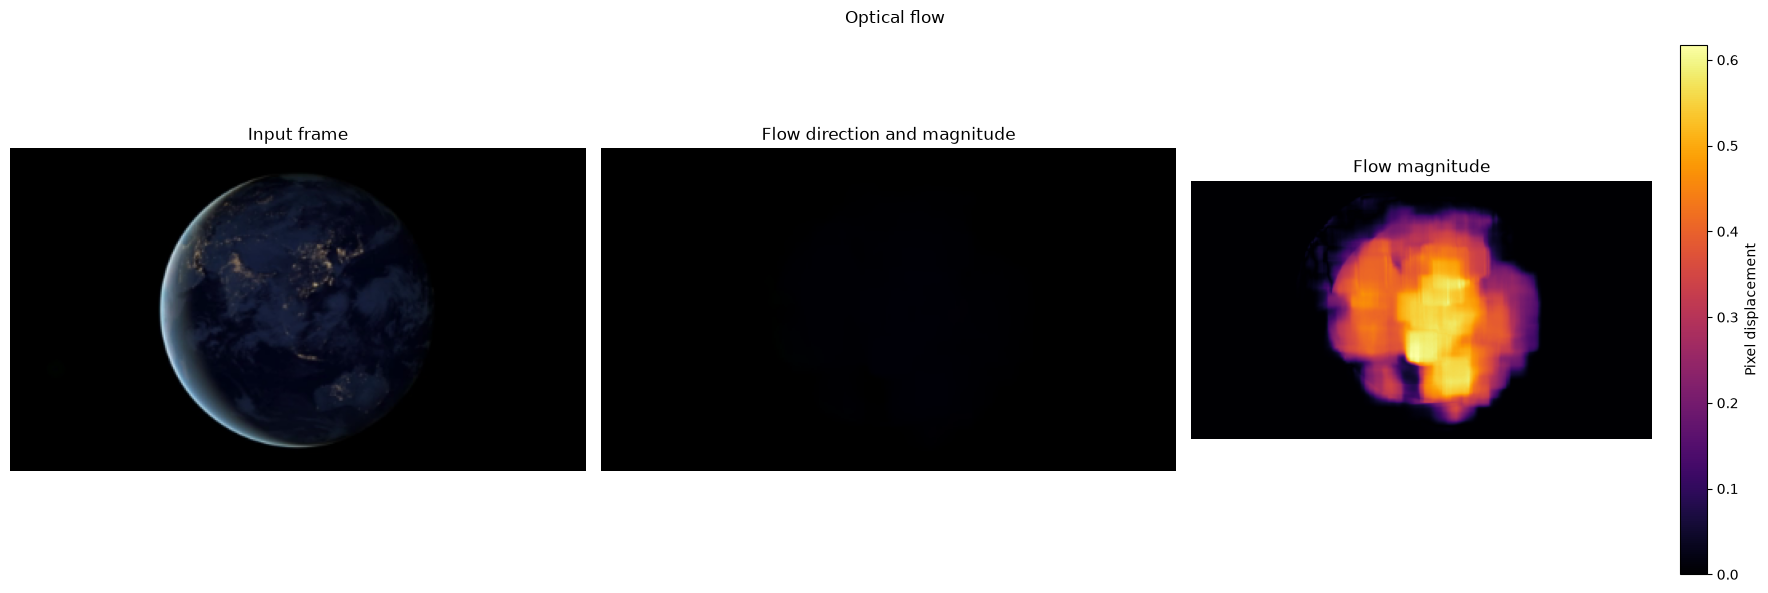

In [15]:
display_flow_result(first)

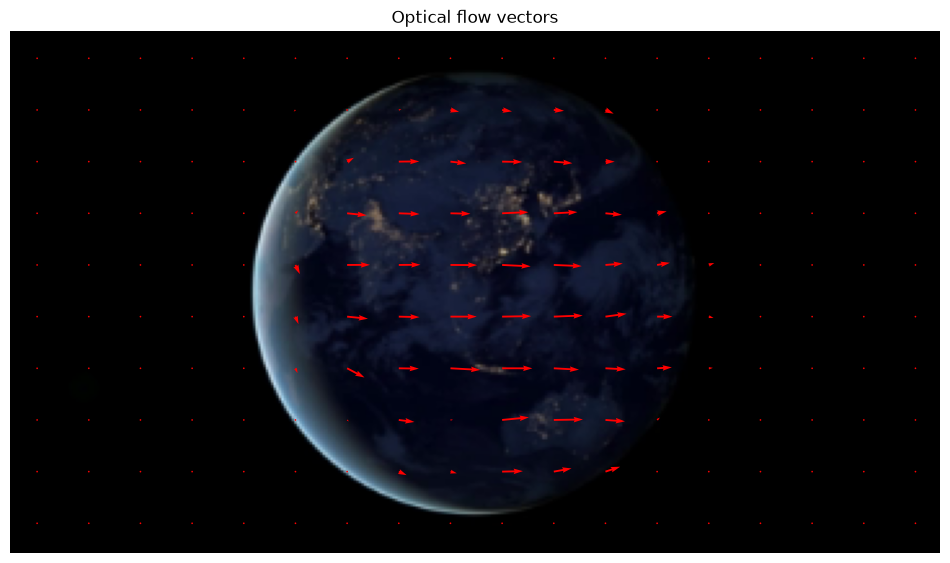

In [13]:
display_flow_vectors(first, 20, 20)